In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch
from torch import nn
import matplotlib.pyplot as plt
import torchvision
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader, Subset
import transformers
from PIL import Image

In [2]:
#pip install -U bitsandbytes>=0.46.1 accelerate

In [3]:
if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

In [4]:
from transformers import AutoProcessor, AutoModel

In [5]:
from pathlib import Path
data_path = Path("data/")

In [6]:
from datasets import load_dataset

In [7]:
image_data_path = data_path / "images" / "train2017"
image_data_path

WindowsPath('data/images/train2017')

In [8]:
vision_model = AutoModel.from_pretrained("google/siglip-base-patch16-384", dtype=torch.bfloat16)
processor = AutoProcessor.from_pretrained("google/siglip-base-patch16-384")

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

In [9]:
for param in vision_model.parameters():
  param.requires_grad = False

In [10]:
import os
import json
import random
from pathlib import Path

def prepare_train():
    # --- SÜRE VE BOYUT AYARLARI  ---
    STAGE1_TOTAL = 15000  # Aşama 1 (Sadece COCO Captions)
    STAGE2_TOTAL = 12000  # Aşama 2 (%40 Sayma, %25 Nesne, %20 Caption, %15 LLaVA)
    EVAL_TOTAL   = 300    # Adım 6: Eğitime hiç girmeyecek "how many" test soruları
    
    data_dir = Path("data")
    images_dir = data_dir / "images" / "train2017"
    ann_dir = data_dir / "vqa_coco_anns"
    ann_dir.mkdir(parents=True, exist_ok=True)
    
    # 1. Resmi COCO Captions ve VQAv2 Anotasyonlarını İndir
    if not (ann_dir / "annotations" / "captions_train2017.json").exists():
        print("⏳ COCO Captions indiriliyor...")
        os.system(f"wget -q http://images.cocodataset.org/annotations/annotations_trainval2017.zip -O {ann_dir}/coco_ann.zip")
        os.system(f"unzip -q -o {ann_dir}/coco_ann.zip -d {ann_dir}/")
    
    if not (ann_dir / "v2_OpenEnded_mscoco_train2017_questions.json").exists():
        print("⏳ VQAv2 Soruları ve Cevapları indiriliyor...")
        os.system(f"wget -q https://s3.amazonaws.com/cvmlp/vqa/mscoco/vqa/v2_Questions_Train_mscoco.zip -O {ann_dir}/vqa_q.zip")
        os.system(f"wget -q https://s3.amazonaws.com/cvmlp/vqa/mscoco/vqa/v2_Annotations_Train_mscoco.zip -O {ann_dir}/vqa_a.zip")
        os.system(f"unzip -q -o {ann_dir}/vqa_q.zip -d {ann_dir}/")
        os.system(f"unzip -q -o {ann_dir}/vqa_a.zip -d {ann_dir}/")
    
    print("📂 JSON dosyaları belleğe okunuyor...")
    with open(ann_dir / "annotations" / "captions_train2017.json", "r") as f:
        coco_captions = json.load(f)["annotations"]
    
    with open(ann_dir / "v2_OpenEnded_mscoco_train2014_questions.json", "r") as f:
        vqa_questions = {q["question_id"]: q for q in json.load(f)["questions"]}
    
    with open(ann_dir / "v2_mscoco_train2014_annotations.json", "r") as f:
        vqa_annotations = json.load(f)["annotations"]
    
    with open(data_dir / "llava_instruct_150k.json", "r") as f:
        llava_raw = json.load(f)
    
    # --- AŞAMA 1 VERİSİ HAZIRLAMA (Rastgele COCO Captions) ---
    random.shuffle(coco_captions)
    stage1_data = []
    for cap in coco_captions:
        if len(stage1_data) >= STAGE1_TOTAL:
            break
        img_path = images_dir / f"{cap['image_id']:012d}.jpg"
        if img_path.exists():
            stage1_data.append({
                "image_path": str(img_path),
                "question": "Describe the image briefly.",
                "answer": cap["caption"].strip()
            })
    
    with open(data_dir / "stage1_captions.json", "w") as f:
        json.dump(stage1_data, f, indent=2)
    print(f"✅ Aşama 1 Verisi Hazır: {len(stage1_data)} örnek -> data/stage1_captions.json")
    
    # --- VQAv2 FİLTRELEME (%40 Sayma, %25 Nesne/Renk) ---
    random.shuffle(vqa_annotations)
    how_many_pool = []
    object_color_pool = []
    
    obj_prefixes = ("what is on", "what color", "what colour", "is there a", "what is the", "where is the")
    
    for ann in vqa_annotations:
        q_type = ann.get("question_type", "").lower()
        ans_str = ann["multiple_choice_answer"].strip()
        q_obj = vqa_questions.get(ann["question_id"])
        if not q_obj:
            continue
    
        q_text = q_obj["question"].strip()
        img_path = images_dir / f"{ann['image_id']:012d}.jpg"
        if not img_path.exists():
            continue
    
        # 1. Sayma Soruları (Sabit cümle formatı ile)
        if q_type == "how many" or q_text.lower().startswith("how many"):
            if ans_str.isdigit() or ans_str in ["zero", "one", "two", "three", "four", "five", "none"]:
                formatted_ans = f"There are {ans_str} in the image." if ans_str != "1" else "There is 1 in the image."
                how_many_pool.append({
                    "image_path": str(img_path),
                    "question": q_text,
                    "answer": formatted_ans,
                    "raw_answer": ans_str
                })
        # 2. Nesne / Renk Soruları
        elif q_text.lower().startswith(obj_prefixes) and len(ans_str.split()) <= 5:
            formatted_ans = f"The answer is {ans_str}."
            object_color_pool.append({
                "image_path": str(img_path),
                "question": q_text,
                "answer": formatted_ans
            })
    
    # Adım 6 için 300 adet "how many" sorusunu eğitimden tamamen ayır
    eval_data = how_many_pool[:EVAL_TOTAL]
    train_how_many = how_many_pool[EVAL_TOTAL:]
    
    with open(data_dir / "eval_how_many.json", "w") as f:
        json.dump(eval_data, f, indent=2)
    print(f"✅ Değerlendirme (Test) Verisi Ayrıldı: {len(eval_data)} örnek -> data/eval_how_many.json")
    
    # --- AŞAMA 2 KARIŞIMI OLUŞTURMA (%40 Sayma, %25 Nesne, %20 Caption, %15 LLaVA) ---
    n_count = int(STAGE2_TOTAL * 0.40)
    n_obj   = int(STAGE2_TOTAL * 0.25)
    n_cap   = int(STAGE2_TOTAL * 0.20)
    n_llava = STAGE2_TOTAL - (n_count + n_obj + n_cap)
    
    stage2_data = []
    stage2_data.extend(random.sample(train_how_many, min(n_count, len(train_how_many))))
    stage2_data.extend(random.sample(object_color_pool, min(n_obj, len(object_color_pool))))
    stage2_data.extend(random.sample(stage1_data, min(n_cap, len(stage1_data))))
    
    # %15 LLaVA kısa/orta diyalogları
    random.shuffle(llava_raw)
    llava_subset = []
    for ex in llava_raw:
        if len(llava_subset) >= n_llava:
            break
        if "image" in ex and len(ex.get("conversations", [])) >= 2:
            q = ex["conversations"][0]["value"].replace("<image>", "").strip()
            a = ex["conversations"][1]["value"].strip()
            img_p = images_dir / ex["image"]
            if len(a.split()) <= 30 and img_p.exists():
                llava_subset.append({"image_path": str(img_p), "question": q, "answer": a})
    
    stage2_data.extend(llava_subset)
    random.shuffle(stage2_data)
    
    with open(data_dir / "stage2_mixed.json", "w") as f:
        json.dump(stage2_data, f, indent=2)
    print(f"✅ Aşama 2 Karışım Verisi Hazır: {len(stage2_data)} örnek -> data/stage2_mixed.json")

In [11]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence
from PIL import Image

# EĞİTİM VE INFERENCE İÇİN TEK ORTAK SYSTEM PROMPT 
SYSTEM_PROMPT = "<|im_start|>system\nYou are a helpful assistant that can see images and answer questions directly and concisely.<|im_end|>\n<|im_start|>user\n"

class VisionProjector(nn.Module):
    def __init__(self):
        super().__init__()
        self.MLP = nn.Sequential(
            nn.Linear(in_features=768, out_features=2048),
            nn.GELU(),
            nn.Linear(in_features=2048, out_features=2048)
        )
    def forward(self, X):
        return self.MLP(X)

class DiskVQADataset(torch.utils.data.Dataset):
    def __init__(self, json_path, processor, tokenizer):
        super().__init__()
        with open(json_path, "r", encoding="utf-8") as f:
            self.dataset = json.load(f)
        self.processor = processor
        self.tokenizer = tokenizer
        self.p1_ids = self.tokenizer(SYSTEM_PROMPT, return_tensors="pt", add_special_tokens=False).input_ids.squeeze(0)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        item = self.dataset[idx]
        image = Image.open(item["image_path"]).convert("RGB")
        pixel_values = self.processor(images=image, return_tensors="pt")["pixel_values"].squeeze(0)

        p3_str = f"{item['question']}<|im_end|>\n<|im_start|>assistant\n"
        p3_ids = self.tokenizer(p3_str, return_tensors="pt", add_special_tokens=False).input_ids.squeeze(0)

        p4_str = f"{item['answer']}<|im_end|>\n"
        p4_ids = self.tokenizer(p4_str, return_tensors="pt", add_special_tokens=False).input_ids.squeeze(0)

        qa_ids = torch.cat([p3_ids, p4_ids], dim=0)
        p3_mask = torch.full((p3_ids.shape[0],), -100, dtype=torch.long)
        qa_labels = torch.cat([p3_mask, p4_ids], dim=0)

        return {"pixel_values": pixel_values, "p1_ids": self.p1_ids, "qa_ids": qa_ids, "qa_labels": qa_labels}

def collate_fn(batch):
    pixel_values = torch.stack([data["pixel_values"] for data in batch])
    p1_ids = torch.stack([data["p1_ids"] for data in batch])
    qa_ids = pad_sequence([data["qa_ids"] for data in batch], batch_first=True, padding_value=tokenizer.pad_token_id)
    qa_labels = pad_sequence([data["qa_labels"] for data in batch], batch_first=True, padding_value=-100)
    return {"pixel_values": pixel_values, "p1_ids": p1_ids, "qa_ids": qa_ids, "qa_labels": qa_labels}

def get_embeds(batch, vision_model, llm_model, projector):
    pixel_values = batch["pixel_values"].to(device=device, dtype=torch.bfloat16)
    p1_ids = batch["p1_ids"].to(device)
    qa_ids = batch["qa_ids"].to(device)
    qa_labels = batch["qa_labels"].to(device)
    batch_size = pixel_values.shape[0]

    vision_layer = vision_model.vision_model.to(device=device, dtype=torch.bfloat16)
    with torch.no_grad():
        hidden_state = vision_layer(pixel_values).last_hidden_state
    image_embeds = projector(hidden_state.to(torch.bfloat16))

    embed_layer = llm_model.get_input_embeddings()
    p1_embeds = embed_layer(p1_ids).to(torch.bfloat16)
    qa_embeds = embed_layer(qa_ids).to(torch.bfloat16)

    input_embeds = torch.cat([p1_embeds, image_embeds, qa_embeds], dim=1)

    p1_mask = torch.full((batch_size, p1_ids.shape[1]), -100, dtype=torch.long, device=device)
    img_mask = torch.full((batch_size, 576), -100, dtype=torch.long, device=device)
    final_labels = torch.cat([p1_mask, img_mask, qa_labels], dim=1)

    p1_att = torch.ones((batch_size, p1_ids.shape[1]), dtype=torch.long, device=device)
    img_att = torch.ones((batch_size, 576), dtype=torch.long, device=device)
    qa_att = (qa_ids != tokenizer.pad_token_id).long()
    attention_mask = torch.cat([p1_att, img_att, qa_att], dim=1)

    return input_embeds, final_labels, attention_mask

# ADIM 5 & ADIM 0: TUTARLI INFERENCE VE SIFIR TENSÖR (KÖRLÜK) TEST FONKSİYONU
def run_inference(image, question, vision_model, llm_model, projector, processor, tokenizer, device, zero_image_test=False):
    llm_model.eval()
    projector.eval()
    vision_model.eval()
    llm_model.config.use_cache = True

    if zero_image_test:
        # Adım 0.2: Görsel yerine tamamen sıfır tensör göndererek gorsele mi odaklandigini yoksa halisunasyon mi gordugunu test ediyoruz
        pixel_values = torch.zeros((1, 3, 384, 384), device=device, dtype=torch.bfloat16)
    else:
        pixel_values = processor(images=image, return_tensors="pt").pixel_values.to(device, dtype=torch.bfloat16)

    with torch.no_grad():
        vision_layer = vision_model.vision_model.to(device=device, dtype=torch.bfloat16)
        vision_outputs = vision_layer(pixel_values)
        image_embeds = projector(vision_outputs.last_hidden_state.to(torch.bfloat16))

        p3_str = f"{question}<|im_end|>\n<|im_start|>assistant\n"
        p1_ids = tokenizer(SYSTEM_PROMPT, return_tensors="pt", add_special_tokens=False).input_ids.to(device)
        p3_ids = tokenizer(p3_str, return_tensors="pt", add_special_tokens=False).input_ids.to(device)

        embed_layer = llm_model.get_input_embeddings()
        p1_embeds = embed_layer(p1_ids).to(torch.bfloat16)
        p3_embeds = embed_layer(p3_ids).to(torch.bfloat16)

        inputs_embeds = torch.cat([p1_embeds, image_embeds, p3_embeds], dim=1)
        attention_mask = torch.ones(inputs_embeds.shape[:2], dtype=torch.long, device=device)

        output_ids = llm_model.generate(
            inputs_embeds=inputs_embeds,
            attention_mask=attention_mask,
            max_new_tokens=30, # Adım 5: Kısa ve net cevaplar için 30 token
            do_sample=False,   # Adım 5: Sayma için deterministik üretim
            repetition_penalty=1.2,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id
        )
    return tokenizer.decode(output_ids[0], skip_special_tokens=True).strip()

In [12]:
vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
if vram_gb > 35:
    BATCH_SIZE = 16
    ACCUM_STEPS = 2
    print(f"🔥 Yüksek Bellekli GPU Algılandı ({vram_gb:.1f} GB)! Batch Size = 16")
elif vram_gb > 15:
    BATCH_SIZE = 8
    ACCUM_STEPS = 4
    print(f"⚡ Orta-Üst Segment GPU Algılandı ({vram_gb:.1f} GB)! Batch Size = 8")
else:
    BATCH_SIZE = 2
    ACCUM_STEPS = 16
    print(f"💻 Giriş Segmenti / Laptop GPU Algılandı ({vram_gb:.1f} GB)! Batch Size = 2")

💻 Giriş Segmenti / Laptop GPU Algılandı (6.0 GB)! Batch Size = 2


In [13]:
import os
import gc
import json
import random
import shutil
import torch
from torch import nn
from torch.utils.data import DataLoader
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, get_cosine_schedule_with_warmup
from peft import prepare_model_for_kbit_training, LoraConfig, get_peft_model
from PIL import Image

for name, module in llm_model.named_modules():
    if "norm" in name or "lm_head" in name or "embed_tokens" in name:
        module.to(torch.bfloat16)

def train_stage_1():
    gc.collect()
    torch.cuda.empty_cache()

    s1_dataset = DiskVQADataset("data/stage1_captions.json", processor, tokenizer)
    s1_loader = DataLoader(s1_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn, shuffle=True, num_workers=2, pin_memory=True)

    llm_model.config.use_cache = False
    llm_model.eval()
    for p in llm_model.parameters():
        p.requires_grad = False
    llm_model.gradient_checkpointing_enable()
    llm_model.enable_input_require_grads()

    projector = VisionProjector().to(device=device, dtype=torch.bfloat16)
    projector.train()

    total_opt_steps = len(s1_loader) // ACCUM_STEPS
    warmup_steps = int(total_opt_steps * 0.05)

    # 5e-4: Hem hızlı yakınsar hem de bfloat16'da patlama yapmaz
    optimizer = torch.optim.AdamW(projector.parameters(), lr=5e-4, weight_decay=1e-2)
    scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_opt_steps)
    optimizer.zero_grad()

    print(f"\n🚀 AŞAMA 1 Başlıyor! Toplam Adım: {len(s1_loader)} (Optimizasyon Adımı: {total_opt_steps})")
    running_loss = 0.0

    for step, batch in enumerate(s1_loader):
        # autocast ile float32 bellek sızıntısını engelliyoruz
        with torch.amp.autocast('cuda', dtype=torch.bfloat16):
            input_embeds, final_labels, attention_mask = get_embeds(batch, vision_model, llm_model, projector)
            outputs = llm_model(inputs_embeds=input_embeds, labels=final_labels, attention_mask=attention_mask)
            raw_loss = outputs.loss.item()
            loss = outputs.loss / ACCUM_STEPS

        running_loss += raw_loss
        loss.backward()

        if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(s1_loader):
            torch.nn.utils.clip_grad_norm_(projector.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()

        if (step + 1) % 50 == 0:
            avg_loss = running_loss / 50
            print(f"Aşama 1 | Adım: {step+1}/{len(s1_loader)} | Ortalama Loss: {avg_loss:.4f} | LR: {scheduler.get_last_lr()[0]:.2e}")
            running_loss = 0.0

    os.makedirs("models_claude", exist_ok=True)
    torch.save(projector.state_dict(), "models_claude/stage1_projector.pt")
    if os.path.exists("/content/drive/MyDrive"):
        os.makedirs("/content/drive/MyDrive/vlm_claude", exist_ok=True)
        shutil.copy("models_claude/stage1_projector.pt", "/content/drive/MyDrive/vlm_claude/stage1_projector.pt")
    print("✅ Aşama 1 Tamamlandı ve Drive'a kaydedildi!")

    #  DOĞRULAMA 
    print("\n🔍 AŞAMA 1 DOĞRULAMA TESTİ (LoRA'sız Saf Model):")
    sample = random.choice(s1_dataset.dataset)
    img = Image.open(sample["image_path"]).convert("RGB")
    pred_real = run_inference(img, "Describe the image briefly.", vision_model, llm_model, projector, processor, tokenizer, device, zero_image_test=False)
    pred_zero = run_inference(img, "Describe the image briefly.", vision_model, llm_model, projector, processor, tokenizer, device, zero_image_test=True)
    print(f"Gerçek Caption : {sample['answer']}")
    print(f"Model (Görselli): {pred_real}")
    print(f"Model (Sıfır T.): {pred_zero}")
    return projector

#trained_s1_projector = train_stage_1()

W1020 21:28:57.348000 13380 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


NameError: name 'llm_model' is not defined

In [ ]:
def train_stage_2(projector):
    global llm_model
    gc.collect()
    torch.cuda.empty_cache()

    s2_dataset = DiskVQADataset("data/stage2_mixed.json", processor, tokenizer)
    s2_loader = DataLoader(s2_dataset, batch_size=BATCH_SIZE, collate_fn=collate_fn, shuffle=True, num_workers=2, pin_memory=True)

    # Şimdi temiz Base Model üzerine LoRA ekliyoruz
    llm_model = prepare_model_for_kbit_training(llm_model)
    lora_config = LoraConfig(
        r=16, lora_alpha=32, lora_dropout=0.05, task_type="CAUSAL_LM",
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
    )
    llm_model = get_peft_model(llm_model, lora_config)

    # prepare_model_for_kbit_training tekrar float32 yapmasın diye bfloat16 kilidini yeniliyoruz
    for name, module in llm_model.named_modules():
        if "norm" in name or "lm_head" in name or "embed_tokens" in name:
            module.to(torch.bfloat16)

    llm_model.config.use_cache = False
    llm_model.gradient_checkpointing_enable()
    llm_model.enable_input_require_grads()
    llm_model.train()
    projector.train()

    trainable_llm_params = [p for p in llm_model.parameters() if p.requires_grad]

    # Adım 4: 2 Epoch, Proj LR: 2e-5, LoRA LR: 1e-4
    epochs = 2
    total_opt_steps = (len(s2_loader) * epochs) // ACCUM_STEPS
    warmup_steps = int(total_opt_steps * 0.03)

    optimizer = torch.optim.AdamW([
        {"params": projector.parameters(), "lr": 2e-5},
        {"params": trainable_llm_params, "lr": 1e-4}
    ], weight_decay=1e-2)

    scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_opt_steps)
    optimizer.zero_grad()

    step_global = 0
    for epoch in range(epochs):
        print(f"\n--- 🚀 AŞAMA 2 | EPOCH {epoch+1}/{epochs} (Toplam Adım: {len(s2_loader)}) ---")
        running_loss = 0.0
        for step, batch in enumerate(s2_loader):
            with torch.amp.autocast('cuda', dtype=torch.bfloat16):
                input_embeds, final_labels, attention_mask = get_embeds(batch, vision_model, llm_model, projector)
                outputs = llm_model(inputs_embeds=input_embeds, labels=final_labels, attention_mask=attention_mask)
                raw_loss = outputs.loss.item()
                loss = outputs.loss / ACCUM_STEPS

            running_loss += raw_loss
            loss.backward()

            if (step_global + 1) % ACCUM_STEPS == 0 or (step + 1) == len(s2_loader):
                torch.nn.utils.clip_grad_norm_(list(projector.parameters()) + trainable_llm_params, max_norm=1.0)
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()

            step_global += 1
            if (step + 1) % 50 == 0:
                avg_loss = running_loss / 50
                print(f"Epoch {epoch+1} | Adım: {step+1}/{len(s2_loader)} | Ortalama Loss: {avg_loss:.4f} | LoRA_LR: {optimizer.param_groups[1]['lr']:.2e}")
                running_loss = 0.0

        ep_dir = f"models_claude/epoch_{epoch+1}"
        os.makedirs(ep_dir, exist_ok=True)
        torch.save(projector.state_dict(), f"{ep_dir}/projector.pt")
        llm_model.save_pretrained(f"{ep_dir}/qwen_lora")
        if os.path.exists("/content/drive/MyDrive"):
            drive_ep = f"/content/drive/MyDrive/vlm_claude/epoch_{epoch+1}"
            shutil.copytree(ep_dir, drive_ep, dirs_exist_ok=True)
        print(f"💾 Epoch {epoch+1} ağırlıkları kaydedildi!")

    return projector

# AŞAMA 1 BİTER BİTMEZ OTOMATİK AŞAMA 2'YE GEÇ:
#trained_s2_proj = train_stage_2(trained_s1_projector)

In [ ]:
import re

def evaluate_counting(projector_to_test, llm_to_test, num_samples=100):
    with open("data/eval_how_many.json", "r") as f:
        eval_items = json.load(f)[:num_samples]

    word_to_num = {"zero": "0", "none": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5", "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10"}
    correct = 0

    print(f"📊 {len(eval_items)} adet görülmemiş 'How Many' sorusu üzerinde doğruluk ölçülüyor...")
    for i, item in enumerate(eval_items):
        img = Image.open(item["image_path"]).convert("RGB")
        pred = run_inference(img, item["question"], vision_model, llm_to_test, projector_to_test, processor, tokenizer, device)

        gt_raw = str(item["raw_answer"]).lower().strip()
        gt_digit = word_to_num.get(gt_raw, gt_raw)

        # Modelin cevabındaki sayıları yakala
        pred_lower = pred.lower()
        for w, d in word_to_num.items():
            pred_lower = re.sub(rf"\b{w}\b", d, pred_lower)

        found_digits = re.findall(r"\b\d+\b", pred_lower)
        is_hit = (gt_digit in found_digits)
        if is_hit:
            correct += 1

        if i < 10: # İlk 10 örneği ekrana yazdır
            print(f"[{i+1}] Soru: {item['question']} | Gerçek: {gt_digit} | Model: '{pred}' -> {'✅' if is_hit else '❌'}")

    acc = (correct / len(eval_items)) * 100
    print("="*50)
    print(f"🎯 Toplam Sayma Doğruluğu (Accuracy): %{acc:.2f} ({correct}/{len(eval_items)})")
    return acc

#evaluate_counting(trained_s2_proj, llm_model, num_samples=100)

In [14]:
import urllib.request
from PIL import Image
import matplotlib.pyplot as plt

def ask_question(gorsel_kaynagi, soru, gorseli_goster=True):
    """
    gorsel_kaynagi: Dosya yolu ("data/.../resim.jpg"), URL ("https://...") veya PIL Image nesnesi
    soru: Modele sormak istediğin İngilizce soru (str) veya sorular listesi (list)
    """
    # 1. Görseli kaynağına göre aç
    if isinstance(gorsel_kaynagi, str):
        if gorsel_kaynagi.startswith("http"):
            req = urllib.request.Request(gorsel_kaynagi, headers={'User-Agent': 'Mozilla/5.0'})
            img = Image.open(urllib.request.urlopen(req)).convert("RGB")
        else:
            img = Image.open(gorsel_kaynagi).convert("RGB")
    else:
        img = gorsel_kaynagi.convert("RGB")

    # 2. Görseli ekrana bas
    if gorseli_goster:
        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.axis("off")
        plt.show()

    # 3. Tek bir soruysa listeye çevir, sırayla modele sor
    sorular = [soru] if isinstance(soru, str) else soru

    for s in sorular:
        cevap = run_inference(
            image=img,
            question=s,
            vision_model=vision_model,
            llm_model=llm_model,
            projector=projector,
            processor=processor,
            tokenizer=tokenizer,
            device=device,
            zero_image_test=False
        )
        print(f"❓ Soru  : {s}")
        print(f"🤖 Model : {cevap}")
        print("-" * 50)

In [18]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, AutoProcessor, AutoModel, BitsAndBytesConfig
from peft import PeftModel, set_peft_model_state_dict
from safetensors.torch import load_file

device = "cuda" if torch.cuda.is_available() else "cpu"

# 1. SigLIP ve Tokenizer
vision_model = AutoModel.from_pretrained("google/siglip-base-patch16-384", torch_dtype=torch.bfloat16).to(device)
vision_model.eval()
processor = AutoProcessor.from_pretrained("google/siglip-base-patch16-384")
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-3B-Instruct")

# 2. Temiz 4-Bit Qwen (Hiçbir prepare_model_for_kbit_training YOK!)
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_use_double_quant=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16
)
base_qwen = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen2.5-3B-Instruct",
    quantization_config=bnb_config,
    torch_dtype=torch.bfloat16,
    device_map="auto"
)

# Eğitimdekiyle birebir aynı bfloat16 dönüşümü
for name, module in base_qwen.named_modules():
    if "norm" in name or "lm_head" in name or "embed_tokens" in name:
        module.to(torch.bfloat16)

# 3. LoRA'yı temiz base_qwen üzerine SADECE BİR KEZ sar
llm_model = PeftModel.from_pretrained(base_qwen, "models/epoch_2/qwen_lora", is_trainable=False)
llm_model.eval()

# 4. Projektörü yükle
projector = VisionProjector().to(device=device, dtype=torch.bfloat16)
projector.load_state_dict(torch.load("models/epoch_2/projector.pt", map_location=device))
projector.eval()

print("✅ Tamamen temiz kurulum tamamlandı!")

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

✅ Tamamen temiz kurulum tamamlandı!


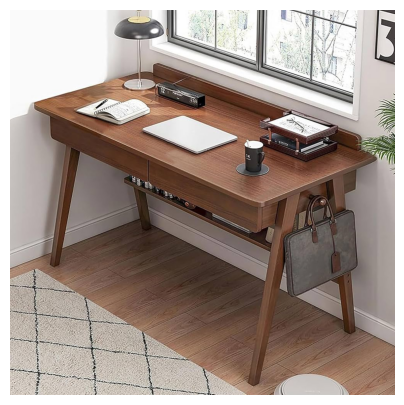

❓ Soru  : is there any laptop on the image?
🤖 Model : The answer is yes.
--------------------------------------------------


In [25]:
img = "https://m.media-amazon.com/images/I/71z7gjh2hoL._AC_UF1000,1000_QL80_.jpg"
question = "is there any laptop on the image?"

ask_question(img,question)